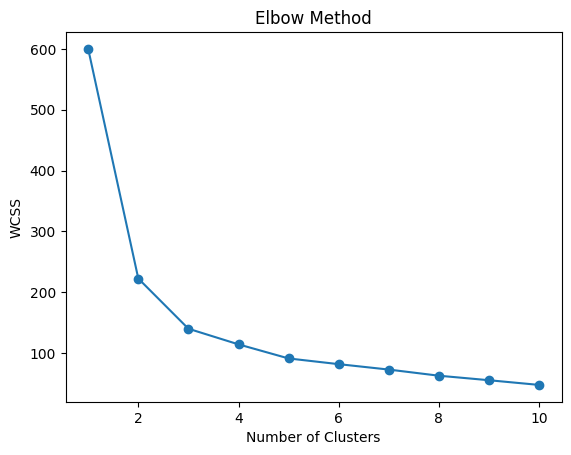

Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Cluster Species  
0        1  setosa  
1        1  setosa  
2        1  setosa  
3        1  setosa  
4        1  setosa  

Species and Cluster:
  Species  Cluster
0  setosa        1
1  setosa        1
2  setosa        1
3  setosa        1
4  setosa        1

Cluster Centers:
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]


In [1]:

# Install libraries:
# python3 -m pip install pandas matplotlib scikit-learn

import pandas as pd
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load dataset
iris = load_iris()

# Convert dataset into DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Select features
X = df

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Apply K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display results
df["Species"] = iris.target_names[iris.target]

print("Dataset:")
print(df.head())

print("\nSpecies and Cluster:")
print(df[["Species", "Cluster"]].head())

print("\nCluster Centers:")
print(kmeans.cluster_centers_)
